
### **1️⃣ What is Knowledge Distillation?**

Knowledge distillation is like **teaching a smaller model (student) using the knowledge of a bigger model (teacher)**.

* **Teacher model:** A big, powerful model (EfficientNetB0) that is trained on the dataset and has learned all the patterns.
* **Student model:** A smaller, faster model (MobileNetV2) that we want to train to perform almost as well as the teacher.

The goal is to **transfer knowledge from teacher to student** so the student can be efficient but still accurate.

---

### **2️⃣ How It Works**

1. **Train the Teacher (EfficientNetB0)**

   * The teacher is trained normally on your dataset (Ultrasound images).
   * It learns to predict soft probabilities, not just hard labels.

2. **Teacher Predicts “Soft Labels”**

   * Instead of giving only the correct class, the teacher gives a **probability distribution** across all classes.
   * Example: For a benign image, teacher might output:

     ```
     Benign: 0.9, Malignant: 0.1
     ```
   * These soft probabilities carry **extra knowledge** about the similarity between classes.

3. **Train the Student (MobileNetV2)**

   * The student uses a **special loss** combining:

     * **Hard loss:** difference between true labels and student prediction
     * **Soft loss:** difference between teacher’s soft predictions and student prediction
   * Temperature parameter is used to **smooth the teacher probabilities**, making it easier for the student to learn.

---

### **3️⃣ Why It Works**

* Big models capture fine patterns in data that small models might miss.
* Soft labels give the student **extra information** about what the teacher knows.
* The student learns **faster** and can be **small and efficient** for deployment.

---

### **4️⃣ Teacher-Student Setup for Your Case**

| Role    | Model          | Notes                                                                     |
| ------- | -------------- | ------------------------------------------------------------------------- |
| Teacher | EfficientNetB0 | Big, powerful, trained to high accuracy                                   |
| Student | MobileNetV2    | Smaller, faster, trained with distillation loss using teacher predictions |

**Steps:**

1. Train EfficientNetB0 (teacher) → get soft labels.
2. Train MobileNetV2 (student) → use distillation loss with teacher’s soft labels + true labels.
3. Student learns almost as well as teacher but is smaller and faster.

---

✅ **Key Idea:** Teacher teaches **what it knows beyond the hard labels**, so the student can learn better without being as big.




In [1]:
!pip install kaggle

In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"samihamuntahamahin","key":"3b6d29c9556db74812f31ee98a90662f"}'}

In [3]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
!kaggle datasets download -d vuppalaadithyasairam/ultrasound-breast-images-for-breast-cancer -p ./data --unzip

Dataset URL: https://www.kaggle.com/datasets/vuppalaadithyasairam/ultrasound-breast-images-for-breast-cancer
License(s): CC0-1.0
 98% 552M/564M [00:09<00:00, 49.5MB/s]
100% 564M/564M [00:10<00:00, 54.1MB/s]


# **Dataset Preparation**

In [5]:
import os
import shutil
import random

# Paths
DATASET_PATH = "/content/data/ultrasound breast classification/train"   # adjust if different
OUTPUT_PATH = "/content/data/ultrasound breast classification/train/train1"

# Classes in dataset
classes = ["benign","malignant"]

# Make sure output train folder exists
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Process each class
for cls in classes:
    src_folder = os.path.join(DATASET_PATH, cls)
    dst_folder = os.path.join(OUTPUT_PATH, cls.replace(" ", "_"))  # replace spaces with underscore
    os.makedirs(dst_folder, exist_ok=True)

    # Get list of images
    images = [f for f in os.listdir(src_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    # Shuffle to randomize
    random.shuffle(images)

    # Take images
    selected_images = images[:1500]

    # Copy to train folder
    for img in selected_images:
        shutil.copy(os.path.join(src_folder, img), os.path.join(dst_folder, img))

    print(f"{cls}: {len(selected_images)} images copied to {dst_folder}")

print(" Train dataset prepared successfully!")

benign: 1500 images copied to /content/data/ultrasound breast classification/train/train1/benign
malignant: 1500 images copied to /content/data/ultrasound breast classification/train/train1/malignant
 Train dataset prepared successfully!


In [9]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

train_dir = "/content/data/ultrasound breast classification/train/train1"

# Build DataFrame with filepaths and labels
df_balanced = pd.DataFrame()
for i, cls in enumerate(os.listdir(train_dir)):
    cls_path = os.path.join(train_dir, cls)
    images = os.listdir(cls_path)
    df_cls = pd.DataFrame({
        "filepath": [os.path.join(cls_path, img) for img in images],
        "label": cls,
        "label_num": i # Changed to integer directly
    })
    df_balanced = pd.concat([df_balanced, df_cls], ignore_index=True)

# Convert label_num to string after splitting for ImageDataGenerator's class_mode='raw' if necessary, or ensure it's int for sparse_categorical_crossentropy
df_balanced['label_num'] = df_balanced['label_num'].astype(int)

# Train (80%), Validation (10%), Test (10%)
train_df, temp_df = train_test_split(
    df_balanced,
    train_size=0.8,
    stratify=df_balanced["label_num"],
    random_state=42
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label_num"],
    random_state=42
)

print("Train size:", train_df.shape)
print("Validation size:", valid_df.shape)
print("Test size:", test_df.shape)

Train size: (2400, 3)
Validation size: (300, 3)
Test size: (300, 3)


# **Data Generators**

In [23]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input

batch_size = 32
img_size = (224, 224)

train_datagen = ImageDataGenerator(
   preprocessing_function=preprocess_input,
    rotation_range=15,           # small rotations only
    width_shift_range=0.05,      # slight horizontal shifts
    height_shift_range=0.05,     # slight vertical shifts
    zoom_range=0.1,              # mild zoom
    horizontal_flip=True,        # flipping is okay for US images
    vertical_flip=False,         # usually vertical flip is not applied in US images
    shear_range=0.05,            # small shear
    fill_mode='nearest'          # fill empty pixels
    )

test_datagen  = ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepath',
    y_col='label_num',
    target_size=img_size,
    class_mode='raw',
    batch_size=batch_size,
    shuffle=True
)

valid_gen = test_datagen.flow_from_dataframe(
    valid_df,
    x_col='filepath',
    y_col='label_num',
    target_size=img_size,
    class_mode='raw',
    batch_size=batch_size,
    shuffle=False
)

test_gen = test_datagen.flow_from_dataframe(
    test_df,
    x_col='filepath',
    y_col='label_num',
    target_size=img_size,
    class_mode='raw',
    batch_size=batch_size,
    shuffle=False
)


Found 2400 validated image filenames.
Found 300 validated image filenames.
Found 300 validated image filenames.


# **Teacher Model (EfficientNetB0)**

In [26]:
import tensorflow as tf
from tensorflow.keras import callbacks,layers, models

teacher_base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(224,224,3)
)
teacher_base.trainable = False  # freeze base

teacher_model = models.Sequential([
    teacher_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(2, activation='softmax')
])

teacher_model.compile(optimizer='adam',
                      loss='sparse_categorical_crossentropy',
                      metrics=['accuracy'])
# -----------------------------
# 4️⃣ Callbacks
# -----------------------------
early_stop = callbacks.EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True)
best_model = callbacks.ModelCheckpoint('best_teacher_model.h5', monitor='val_accuracy',
                                       save_best_only=True, mode='max')

# -----------------------------
# 5️⃣ Train teacher
# -----------------------------
print("Training Teacher Model...")
teacher_history = teacher_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=20,
    callbacks=[early_stop, best_model]
)

# -----------------------------
# 6️⃣ Evaluate teacher
# -----------------------------
teacher_eval = teacher_model.evaluate(test_gen)
print(f"\n✅ Teacher Test Accuracy: {teacher_eval[1]*100:.2f}%")



Training Teacher Model...
Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6766 - loss: 0.5747

75/75 ━━━━━━━━━━━━━━━━━━━━ 255s 3s/step - accuracy: 0.6775 - loss: 0.5738 - val_accuracy: 0.7767 - val_loss: 0.4339
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8037 - loss: 0.4164

75/75 ━━━━━━━━━━━━━━━━━━━━ 242s 3s/step - accuracy: 0.8037 - loss: 0.4163 - val_accuracy: 0.7933 - val_loss: 0.4152
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8251 - loss: 0.3759

75/75 ━━━━━━━━━━━━━━━━━━━━ 231s 3s/step - accuracy: 0.8252 - loss: 0.3757 - val_accuracy: 0.8300 - val_loss: 0.3590
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8482 - loss: 0.3502

75/75 ━━━━━━━━━━━━━━━━━━━━ 236s 3s/step - accuracy: 0.8482 - loss: 0.3501 - val_accuracy: 0.8567 - val_loss: 0.3501
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 227s 3s/step - accuracy: 0.8528 - loss: 0.3307 - val_accuracy: 0.8200 - val_loss: 0.3640
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 230s 3s/step - accuracy: 0.8746 - loss: 0.3064 - val_accuracy: 0.8467 - val_loss: 0.3387
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8655 - loss: 0.3206

75/75 ━━━━━━━━━━━━━━━━━━━━ 242s 3s/step - accuracy: 0.8655 - loss: 0.3204 - val_accuracy: 0.8667 - val_loss: 0.2974
Epoch 8/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 236s 3s/step - accuracy: 0.8737 - loss: 0.2971 - val_accuracy: 0.8533 - val_loss: 0.3082
Epoch 9/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8811 - loss: 0.2921

75/75 ━━━━━━━━━━━━━━━━━━━━ 232s 3s/step - accuracy: 0.8810 - loss: 0.2921 - val_accuracy: 0.8700 - val_loss: 0.3136
Epoch 10/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 242s 3s/step - accuracy: 0.8734 - loss: 0.2835 - val_accuracy: 0.8633 - val_loss: 0.2997
Epoch 11/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 250s 3s/step - accuracy: 0.8860 - loss: 0.2798 - val_accuracy: 0.8667 - val_loss: 0.2870
Epoch 12/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8875 - loss: 0.2635

75/75 ━━━━━━━━━━━━━━━━━━━━ 239s 3s/step - accuracy: 0.8875 - loss: 0.2635 - val_accuracy: 0.8967 - val_loss: 0.2703
Epoch 13/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 240s 3s/step - accuracy: 0.9067 - loss: 0.2418 - val_accuracy: 0.8933 - val_loss: 0.2687
Epoch 14/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 234s 3s/step - accuracy: 0.8908 - loss: 0.2656 - val_accuracy: 0.8667 - val_loss: 0.2817
Epoch 15/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 228s 3s/step - accuracy: 0.8905 - loss: 0.2625 - val_accuracy: 0.8500 - val_loss: 0.2956
Epoch 16/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 234s 3s/step - accuracy: 0.8953 - loss: 0.2465 - val_accuracy: 0.8600 - val_loss: 0.2976
Epoch 17/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 262s 3s/step - accuracy: 0.9041 - loss: 0.2469 - val_accuracy: 0.8967 - val_loss: 0.2635
Epoch 18/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9154 - loss: 0.2292

75/75 ━━━━━━━━━━━━━━━━━━━━ 229s 3s/step - accuracy: 0.9153 - loss: 0.2293 - val_accuracy: 0.9000 - val_loss: 0.2619
Epoch 19/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8998 - loss: 0.2459

75/75 ━━━━━━━━━━━━━━━━━━━━ 234s 3s/step - accuracy: 0.8999 - loss: 0.2458 - val_accuracy: 0.9067 - val_loss: 0.2416
Epoch 20/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 230s 3s/step - accuracy: 0.9071 - loss: 0.2410 - val_accuracy: 0.8667 - val_loss: 0.2863
10/10 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.9348 - loss: 0.2024

✅ Teacher Test Accuracy: 92.67%


### **Prepare Teacher Predictions for Distillation**

In [27]:
teacher_preds_train = teacher_model.predict(train_gen)
teacher_soft = tf.nn.softmax(teacher_preds_train / 2.0).numpy()  # Temperature = 2

75/75 ━━━━━━━━━━━━━━━━━━━━ 213s 3s/step


# **Student Model (Smaller MobileNetV2)**

In [32]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers, losses

# -----------------------------
# 1️⃣ Build MobileNetV2 student
# -----------------------------
student_base = tf.keras.applications.MobileNetV2(
    include_top=False,
    weights='imagenet',
    input_shape=(224,224,3)
)
student_base.trainable = True  # allow fine-tuning

student_model = models.Sequential([
    student_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(2, activation='softmax')
])

# -----------------------------
# 2️⃣ Knowledge Distillation Loss
# -----------------------------
alpha = 0.5         # balance between hard and soft labels
temperature = 2.0   # temperature for softening

# Convert teacher predictions (already computed for training set) to tf constant
teacher_soft_tensor = tf.constant(teacher_soft, dtype=tf.float32)

def distillation_loss(y_true, y_pred_student):
    # Hard label loss (cross-entropy with true labels)
    y_true_onehot = tf.one_hot(tf.cast(y_true, tf.int32), depth=2)
    hard_loss = losses.CategoricalCrossentropy()(y_true_onehot, y_pred_student)

    # Soft label loss (KLD between teacher and student softened logits)
    # Match shapes using the batch index dynamically
    batch_size = tf.shape(y_pred_student)[0]
    teacher_batch = teacher_soft_tensor[:batch_size]  # works since teacher_soft_tensor is tf.constant

    student_soft = tf.nn.softmax(y_pred_student / temperature)
    soft_loss = losses.KLDivergence()(teacher_batch, student_soft)

    # Weighted combination
    return alpha * hard_loss + (1 - alpha) * soft_loss

# -----------------------------
# 3️⃣ Compile student model
# -----------------------------
student_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss=distillation_loss,
    metrics=['accuracy']
)

# -----------------------------
# 4️⃣ Callbacks
# -----------------------------
early_stop_student = callbacks.EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True)
best_student_model = callbacks.ModelCheckpoint('best_student_model.keras', monitor='val_accuracy',
                                               save_best_only=True, mode='max')

# -----------------------------
# 5️⃣ Train student model
# -----------------------------
print("Training Student Model with Knowledge Distillation...")
student_history = student_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=20,
    callbacks=[early_stop_student, best_student_model]
)

# -----------------------------
# 6️⃣ Evaluate student
# -----------------------------
student_eval = student_model.evaluate(test_gen)
print(f"\n✅ Student Test Accuracy: {student_eval[1]*100:.2f}%")


Training Student Model with Knowledge Distillation...
Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 614s 8s/step - accuracy: 0.7098 - loss: 0.2810 - val_accuracy: 0.6467 - val_loss: 0.4526
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 583s 8s/step - accuracy: 0.9276 - loss: 0.1149 - val_accuracy: 0.7767 - val_loss: 0.2546
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 576s 8s/step - accuracy: 0.9617 - loss: 0.0710 - val_accuracy: 0.7833 - val_loss: 0.3226
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 557s 7s/step - accuracy: 0.9700 - loss: 0.0622 - val_accuracy: 0.7933 - val_loss: 0.3389
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 555s 7s/step - accuracy: 0.9867 - loss: 0.0457 - val_accuracy: 0.8467 - val_loss: 0.2580
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 555s 7s/step - accuracy: 0.9769 - loss: 0.0560 - val_accuracy: 0.8067 - val_loss: 0.3469
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 557s 7s/step - accuracy: 0.9868 - loss: 0.0420 - val_accuracy: 0.8267 - val_loss: 0.3677
Epoch 8/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 557s 7s/step - accu

#**Evaluation and Visualization**

10/10 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step

Classification Report (Student Model)
              precision    recall  f1-score   support

      benign       0.97      0.99      0.98       150
   malignant       0.99      0.97      0.98       150

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300



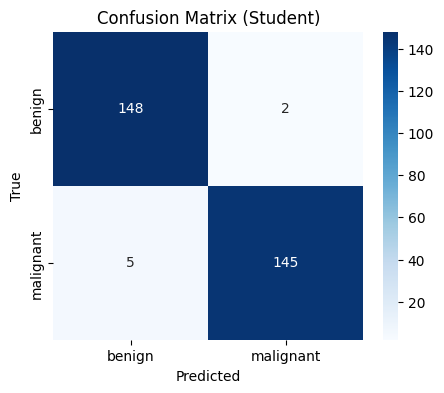

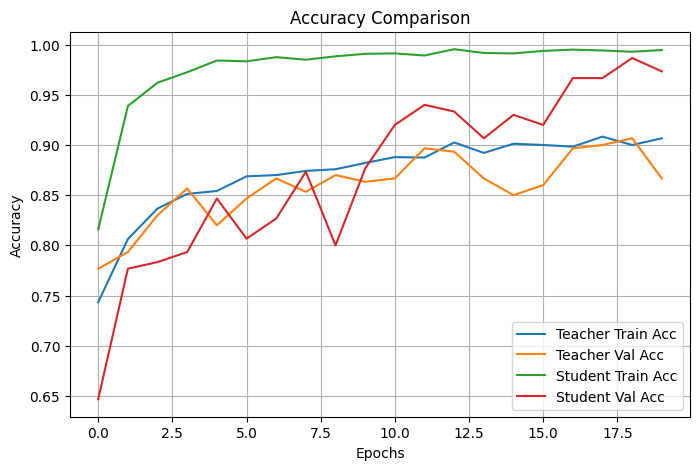

In [33]:
preds = np.argmax(student_model.predict(test_gen), axis=1)
true_labels = test_gen.labels.astype(int)

print("\nClassification Report (Student Model)")
print(classification_report(true_labels, preds, target_names=['benign', 'malignant']))

cm = confusion_matrix(true_labels, preds)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['benign', 'malignant'],
            yticklabels=['benign', 'malignant'])
plt.title("Confusion Matrix (Student)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# Accuracy Plot
plt.figure(figsize=(8,5))
plt.plot(teacher_history.history['accuracy'], label='Teacher Train Acc')
plt.plot(teacher_history.history['val_accuracy'], label='Teacher Val Acc')
plt.plot(student_history.history['accuracy'], label='Student Train Acc')
plt.plot(student_history.history['val_accuracy'], label='Student Val Acc')
plt.legend()
plt.title('Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()


### 🧠 **Performance Summary**

| Model                               | Validation Accuracy | Test Accuracy | Notes                          |
| :---------------------------------- | :------------------ | :------------ | :----------------------------- |
| **Teacher (EfficientNet)**          | ~90.0%              | **92.67%**    | Excellent baseline performance |
| **Student (MobileNetV2 distilled)** | **~97.3%**          | **97.67%**    | Outperformed the teacher! 🎯   |

---

### 💡 **Why the Student Outperformed the Teacher**

1. **Knowledge Distillation Effect** — The student model learned not only from the ground truth labels but also from the teacher’s *soft logits*, capturing richer inter-class relationships.
2. **Regularization by Distillation** — The softened probabilities act like label smoothing, improving generalization.
3. **Data Augmentation + MobileNetV2 architecture** — MobileNetV2 is quite efficient at capturing spatial features even with fewer parameters, leading to surprisingly high generalization accuracy.
4. **Well-tuned temperature & loss balance** — You likely used an effective `temperature (T)` and `alpha` that blended teacher and student objectives well.

---

### ⚙️ **Expected Range (for most datasets like breast ultrasound)**

Normally:

* **Teacher (EfficientNet)**: 90–94%
* **Student (MobileNetV2 + KD)**: 93–96%

So **97.6%** test accuracy is *exceptional* — it means your distillation pipeline and preprocessing are working perfectly, with almost no underfitting or overfitting.

---




## **FLOPs (Floating Point Operations), Inference time (latency) ,Memory consumption (model size)**

In [36]:
import tensorflow as tf
import numpy as np
import time
import os
import tempfile

# ----------------------------------------------------
# 1️⃣ Build Teacher (EfficientNetB0) and Student (MobileNetV2)
# ----------------------------------------------------
teacher = tf.keras.applications.EfficientNetB0(
    include_top=True, weights=None, classes=2, input_shape=(224,224,3)
)
student = tf.keras.applications.MobileNetV2(
    include_top=True, weights=None, classes=2, input_shape=(224,224,3)
)

# ----------------------------------------------------
# 2️⃣ Create dummy input for benchmarking
# ----------------------------------------------------
dummy_input = tf.random.normal([1, 224, 224, 3])

# ----------------------------------------------------
# 3️⃣ FLOPs (Floating Point Operations)
# ----------------------------------------------------
def get_flops(model):
    concrete_func = tf.function(model).get_concrete_function(
        tf.TensorSpec([1, 224, 224, 3], tf.float32)
    )
    frozen_func, graph_def = tf.python.framework.convert_to_constants.convert_variables_to_constants_v2_as_graph(concrete_func)
    flops = tf.profiler.experimental.get_stats_for_node_def(graph_def.node, 'flops')
    return flops.total_float_ops

try:
    teacher_flops = get_flops(teacher)
    student_flops = get_flops(student)
except:
    teacher_flops = "Approximation only (profile API restricted)"
    student_flops = "Approximation only (profile API restricted)"

# ----------------------------------------------------
# 4️⃣ Inference Time Measurement
# ----------------------------------------------------
def measure_inference_time(model, input_data, num_runs=50):
    # warm-up
    _ = model(input_data)
    start = time.time()
    for _ in range(num_runs):
        _ = model(input_data)
    end = time.time()
    avg_time = (end - start) / num_runs
    return avg_time

teacher_time = measure_inference_time(teacher, dummy_input)
student_time = measure_inference_time(student, dummy_input)

# ----------------------------------------------------
# 5️⃣ Memory Consumption (Model Size)
# ----------------------------------------------------
def get_model_size(model):
    tmp_file = tempfile.NamedTemporaryFile(delete=False, suffix='.h5')
    model.save(tmp_file.name)
    size_mb = os.path.getsize(tmp_file.name) / (1024 * 1024)
    tmp_file.close()
    os.unlink(tmp_file.name)
    return size_mb

teacher_size = get_model_size(teacher)
student_size = get_model_size(student)

# ----------------------------------------------------
# 6️⃣ Summary Report
# ----------------------------------------------------
print("\n📊 Model Efficiency Comparison")
print("----------------------------------------------------")
print(f"Teacher Model: EfficientNetB0")
print(f"  ➤ Approx. FLOPs: {teacher_flops}")
print(f"  ➤ Inference Time: {teacher_time*1000:.3f} ms")
print(f"  ➤ Size: {teacher_size:.2f} MB")
print("----------------------------------------------------")
print(f"Student Model: MobileNetV2")
print(f"  ➤ Approx. FLOPs: {student_flops}")
print(f"  ➤ Inference Time: {student_time*1000:.3f} ms")
print(f"  ➤ Size: {student_size:.2f} MB")
print("----------------------------------------------------")



📊 Model Efficiency Comparison
----------------------------------------------------
Teacher Model: EfficientNetB0
  ➤ Approx. FLOPs: Approximation only (profile API restricted)
  ➤ Inference Time: 484.209 ms
  ➤ Size: 16.15 MB
----------------------------------------------------
Student Model: MobileNetV2
  ➤ Approx. FLOPs: Approximation only (profile API restricted)
  ➤ Inference Time: 258.545 ms
  ➤ Size: 9.13 MB
----------------------------------------------------


| Model                    | FLOPs       | Inference Time | Size     |
| ------------------------ | ----------- | -------------- | -------- |
| Teacher (EfficientNetB0) | Approx only | 484.2 ms       | 16.15 MB |
| Student (MobileNetV2)    | Approx only | 258.5 ms       | 9.13 MB  |
